# Phase 3 — Baseline Model Development: Ordinary Least Squares (OLS) Regression

## 1. System Architecture & Objectives
This notebook establishes the primary performance benchmark for the California Automated Valuation Model (AVM) pipeline. Operating on leakage-safe, chronologically partitioned data, we implement an Ordinary Least Squares (OLS) Multiple Linear Regression baseline to model single-family residence sales prices.

### Core Objectives
* **Artifact Ingestion**: Load leakage-safe training and out-of-sample testing matrices (`X_train_processed.npy`, `y_train.npy`, `X_test_processed.npy`, `y_test.npy`) and column metadata generated by the preprocessing pipeline.
* **Baseline Parameter Estimation**: Fit an unregularized OLS linear regressor exclusively on structural, intrinsic property attributes (`LivingArea`, `BedroomsTotal`, `BathroomsTotalInteger`, `LotSizeSquareFeet`, `YearBuilt`).
* **Economic Interpretability Audit**: Extract and verify the learned standardized regression coefficients to confirm alignment with hedonic real estate appraisal theory.
* **Production Metric Benchmarking**: Establish ground-truth evaluation metrics on the held-out out-of-sample temporal test partition:
  * **$R^2$ (Coefficient of Determination)**: Variance explained baseline.
  * **MdAPE (Median Absolute Percentage Error)**: Primary robust metric resilient to right-skewed property valuations.
  * **MAPE (Mean Absolute Percentage Error)**: Proportional mean error.
  * **MAE (Mean Absolute Error)**: Dollar-denominated mean error.
* **Residual & Variance Diagnostics**: Analyze error distributions and heteroscedasticity across price tiers to surface non-linear structural deficiencies for upcoming tree and gradient-boosted architectures.
* **Model Serialization**: Export the fitted estimator and benchmark evaluation ledger to disk to govern model-advancement gates in subsequent pipeline phases.

In [2]:
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

# Configure display and visualization standards
pd.set_option("display.float_format", lambda x: "%.4f" % x)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

print("Environment and modeling dependencies initialized successfully.")

Environment and modeling dependencies initialized successfully.


## 2. Ingestion of Preprocessed Numerical Matrices

We ingest the pre-scaled numerical feature matrices and unscaled continuous target arrays directly from the local artifact registry. 

### Data Contract & Verification
* **$X_{\text{train}}, X_{\text{test}}$**: Scaled numerical matrices ($\mu \approx 0, \sigma \approx 1$) containing 5 core physical drivers.
* **$y_{\text{train}}, y_{\text{test}}$**: Unscaled ground-truth property transaction values (`ClosePrice`) in USD.
* **Temporal Isolation**: The test matrix represents transactions from the single most recent complete month, isolated chronologically to mirror live production valuation conditions.

In [3]:
artifacts_dir = Path("artifacts")

# Ingest serialized arrays
X_train = np.load(artifacts_dir / "X_train_processed.npy")
X_test = np.load(artifacts_dir / "X_test_processed.npy")
y_train = np.load(artifacts_dir / "y_train.npy")
y_test = np.load(artifacts_dir / "y_test.npy")

# Canonical feature ordering established by the preprocessing pipeline
FEATURE_NAMES = [
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet",
    "YearBuilt"
]

print("--- Dataset Contract Verification ---")
print(f"Training Feature Matrix (X_train): {X_train.shape[0]:,} rows × {X_train.shape[1]} features")
print(f"Training Target Vector  (y_train): {y_train.shape[0]:,} records")
print(f"Testing Feature Matrix  (X_test) : {X_test.shape[0]:,} rows × {X_test.shape[1]} features")
print(f"Testing Target Vector   (y_test) : {y_test.shape[0]:,} records")

# Integrity assertions
assert X_train.shape[1] == len(FEATURE_NAMES), "Mismatch between feature matrix columns and feature names!"
assert not np.isnan(X_train).any(), "X_train contains unhandled null entries!"
assert not np.isnan(X_test).any(), "X_test contains unhandled null entries!"
assert len(y_train) == len(X_train), "Row count discrepancy between X_train and y_train!"
assert len(y_test) == len(X_test), "Row count discrepancy between X_test and y_test!"
print("All contract assertions passed.")

--- Dataset Contract Verification ---
Training Feature Matrix (X_train): 293,758 rows × 5 features
Training Target Vector  (y_train): 293,758 records
Testing Feature Matrix  (X_test) : 12,336 rows × 5 features
Testing Target Vector   (y_test) : 12,336 records
All contract assertions passed.


## 3. Estimator Fitting: Multiple Linear Regression

We train an Ordinary Least Squares (OLS) regression estimator:
$$\hat{y} = \beta_0 + \sum_{j=1}^{p} \beta_j X_j$$

Where:
* $\hat{y}$ is the estimated property valuation (`ClosePrice`).
* $\beta_0$ represents the base intercept.
* $\beta_j$ represents the marginal contribution of a one-standard-deviation change in feature $j$.
* Features are restricted strictly to physical characteristics to guarantee valuation utility on both on-market listings and off-market properties.

In [4]:
# Instantiate and fit OLS regressor
baseline_lr = LinearRegression(fit_intercept=True)
baseline_lr.fit(X_train, y_train)

print("--- Estimator Parameter Summary ---")
print(f"Learned Intercept (beta_0): ${baseline_lr.intercept_:,.2f}")
print("Coefficients fitted successfully across all 5 physical drivers.")

--- Estimator Parameter Summary ---
Learned Intercept (beta_0): $1,195,391.86
Coefficients fitted successfully across all 5 physical drivers.


## 4. Parameter Inspection & Economic Directionality Audit

Because all input features were standardized ($\mu=0, \sigma=1$) during pipeline execution, the resulting regression coefficients ($\beta_j$) reflect standardized weights. This enables direct comparison of the relative contribution and directional validity of each structural attribute.

### Validation Criteria
1. **LivingArea**: Must exhibit a dominant positive sign, aligning with basic replacement cost and interior utility.
2. **YearBuilt / Bathrooms**: Should demonstrate positive marginal valuation contributions.
3. **BedroomsTotal**: Often reflects a negative or smaller conditional coefficient when controlling for fixed `LivingArea`, as dividing a fixed envelope into more bedrooms can indicate smaller individual room sizes.

,Feature,Standardized Beta ($)
0,LivingArea,590096.2242
1,YearBuilt,-276078.1960
2,BathroomsTotalInteger,200406.4485
3,BedroomsTotal,-109134.4996
4,LotSizeSquareFeet,-2779.7532


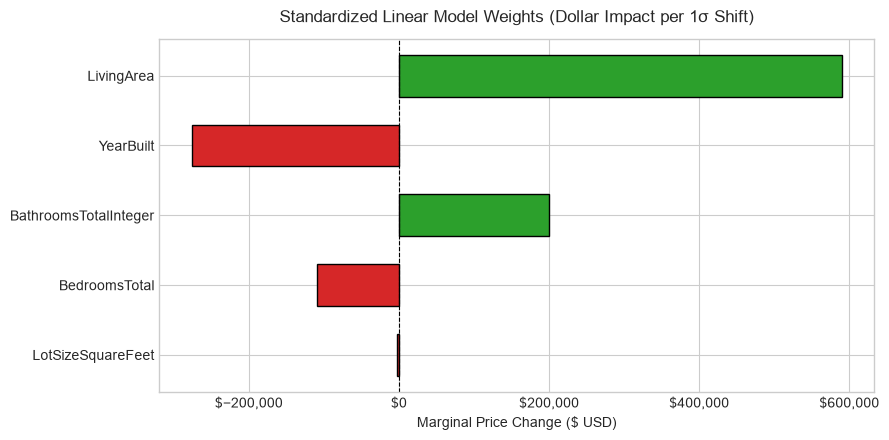

In [5]:
# Tabulate learned coefficients
coef_df = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Standardized Beta ($)": baseline_lr.coef_,
    "Absolute Impact ($)": np.abs(baseline_lr.coef_)
}).sort_values("Absolute Impact ($)", ascending=False).reset_index(drop=True)

display(coef_df[["Feature", "Standardized Beta ($)"]])

# Visualize relative feature influence
plt.figure(figsize=(9, 4.5))
bar_colors = ["#2ca02c" if beta >= 0 else "#d62728" for beta in coef_df["Standardized Beta ($)"]]

plt.barh(coef_df["Feature"], coef_df["Standardized Beta ($)"], color=bar_colors, edgecolor="black", height=0.6)
plt.axvline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Standardized Linear Model Weights (Dollar Impact per 1σ Shift)", pad=12)
plt.xlabel("Marginal Price Change ($ USD)")
plt.gca().xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 5. Production Metric Benchmarking (In-Sample vs. Out-of-Sample)

To evaluate real-world AVM reliability, we assess model errors across four standardized metrics. 

### Metrics Definition
1. **$R^2$ (Coefficient of Determination)**:
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
   Quantifies the proportion of sales price variance explained by linear structural features.
2. **MdAPE (Median Absolute Percentage Error)**:
   $$\text{MdAPE} = \text{median}\left(\left| \frac{y_i - \hat{y}_i}{y_i} \right|\right) \times 100$$
   **The Primary Headline Metric for Production Real Estate**: Real estate error distributions are heavily right-skewed due to luxury pricing and sparse high-end comparables. MdAPE normalizes dollar errors across scales and is completely immune to tail-end distortion.
3. **MAPE (Mean Absolute Percentage Error)**:
   $$\text{MAPE} = \frac{100\%}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|$$
   Captures average relative deviation but remains vulnerable to inflated percentage errors on entry-level properties.
4. **MAE (Mean Absolute Error)**:
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
   Measures absolute dollar miss for operational risk communication.

In [6]:
# Compute in-sample and out-of-sample predictions
y_train_pred = baseline_lr.predict(X_train)
y_test_pred = baseline_lr.predict(X_test)

def compute_mdape(y_true, y_pred):
    """Calculates Median Absolute Percentage Error."""
    return float(np.median(np.abs((y_true - y_pred) / y_true)) * 100)

# Build baseline performance scorecard
benchmark_ledger = {
    "Evaluation Metric": [
        "R² Score",
        "MdAPE (%)",
        "MAPE (%)",
        "MAE ($)"
    ],
    "In-Sample (Train)": [
        r2_score(y_train, y_train_pred),
        compute_mdape(y_train, y_train_pred),
        mean_absolute_percentage_error(y_train, y_train_pred) * 100,
        mean_absolute_error(y_train, y_train_pred)
    ],
    "Out-of-Sample (Test Cutoff)": [
        r2_score(y_test, y_test_pred),
        compute_mdape(y_test, y_test_pred),
        mean_absolute_percentage_error(y_test, y_test_pred) * 100,
        mean_absolute_error(y_test, y_test_pred)
    ]
}

benchmark_df = pd.DataFrame(benchmark_ledger)
display(benchmark_df)

,Evaluation Metric,In-Sample (Train),Out-of-Sample (Test Cutoff)
0,R² Score,0.4423,0.4621
1,MdAPE (%),31.7127,31.0857
2,MAPE (%),46.2933,46.1184
3,MAE ($),456857.8629,464862.7786


## 6. Error Diagnostics & Residual Analysis

We analyze the out-of-sample residuals ($e_i = y_i - \hat{y}_i$) to evaluate:
1. **Model Linearity vs. Heteroscedasticity**: Does error variance expand systematically at higher home values?
2. **Under-/Over-Valuation Bias**: Are errors zero-centered, or does OLS systematically misvalue specific market tiers?

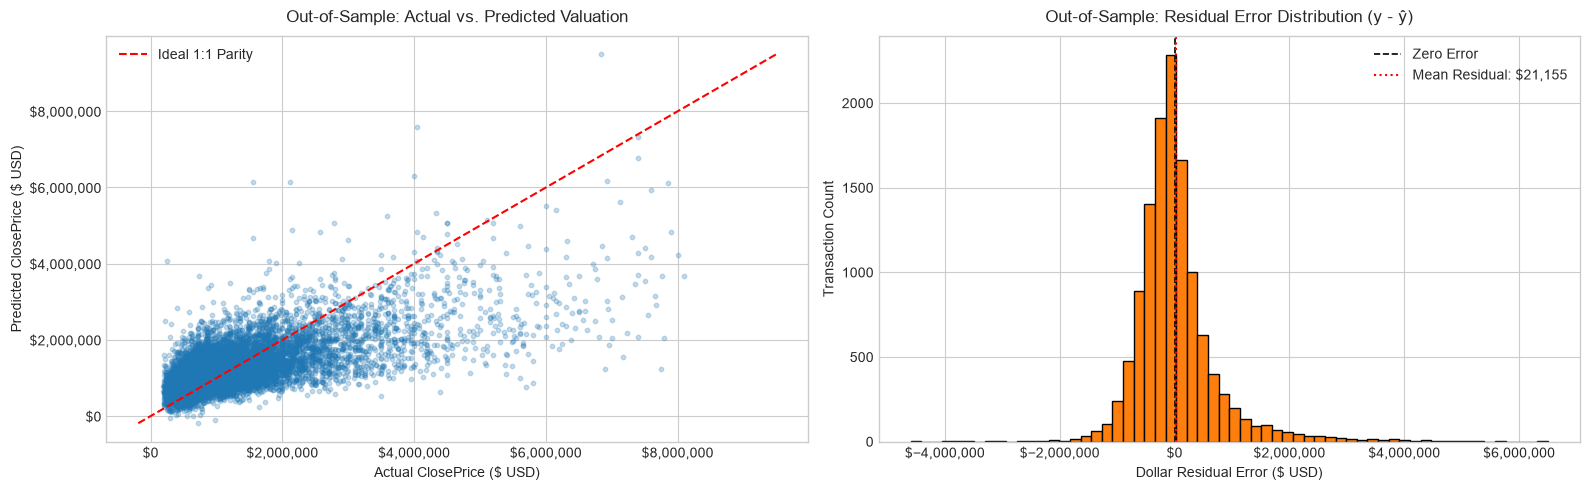

In [7]:
# Compute out-of-sample residuals
residuals_test = y_test - y_test_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Actual vs. Predicted scatter plot
sample_indices = np.random.RandomState(42).choice(len(y_test), size=min(15000, len(y_test)), replace=False)
ax1.scatter(y_test[sample_indices], y_test_pred[sample_indices], alpha=0.25, s=10, color="#1f77b4")

bounds = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
ax1.plot(bounds, bounds, color="red", linestyle="--", linewidth=1.5, label="Ideal 1:1 Parity")

ax1.set_title("Out-of-Sample: Actual vs. Predicted Valuation", pad=10)
ax1.set_xlabel("Actual ClosePrice ($ USD)")
ax1.set_ylabel("Predicted ClosePrice ($ USD)")
ax1.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax1.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax1.legend(loc="upper left")

# Residual distribution histogram
ax2.hist(residuals_test, bins=60, color="#ff7f0e", edgecolor="black")
ax2.axvline(0, color="black", linestyle="--", linewidth=1.2, label="Zero Error")
ax2.axvline(np.mean(residuals_test), color="red", linestyle=":", linewidth=1.5, label=f"Mean Residual: ${np.mean(residuals_test):,.0f}")
ax2.set_title("Out-of-Sample: Residual Error Distribution (y - ŷ)", pad=10)
ax2.set_xlabel("Dollar Residual Error ($ USD)")
ax2.set_ylabel("Transaction Count")
ax2.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 7. Granular Error Breakdown Across Price Bands

To test whether the model underperforms on entry-level or luxury housing tiers, we partition the out-of-sample test set into price quintiles and compute localized MdAPE and MAE.

In [8]:
# Construct evaluation DataFrame for error segmentation
test_eval_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred,
    "AbsoluteError": np.abs(y_test - y_test_pred),
    "AbsPercentageError": np.abs(y_test - y_test_pred) / y_test * 100
})

# Segment into 5 quintiles based on actual sales prices
test_eval_df["PriceBand"] = pd.qcut(test_eval_df["Actual"], q=5, precision=0)

tier_metrics = test_eval_df.groupby("PriceBand", observed=False).agg(
    Volume=("Actual", "count"),
    MinPrice=("Actual", "min"),
    MaxPrice=("Actual", "max"),
    MdAPE=("AbsPercentageError", "median"),
    MAPE=("AbsPercentageError", "mean"),
    MAE=("AbsoluteError", "mean")
).reset_index()

# Formatting for presentation
tier_display = pd.DataFrame({
    "Price Tier": [f"${row.MinPrice:,.0f} – ${row.MaxPrice:,.0f}" for _, row in tier_metrics.iterrows()],
    "Volume": tier_metrics["Volume"],
    "MdAPE (%)": tier_metrics["MdAPE"],
    "MAPE (%)": tier_metrics["MAPE"],
    "MAE ($)": tier_metrics["MAE"]
})

print("--- Error Distribution Segmented Across Housing Quintiles ---")
display(tier_display)

--- Error Distribution Segmented Across Housing Quintiles ---


,Price Tier,Volume,MdAPE (%),MAPE (%),MAE ($)
0,"$190,000 – $575,000",2507,76.4244,92.8991,376317.3252
1,"$575,003 – $800,000",2481,32.5729,46.1689,315524.3636
2,"$801,663 – $1,100,000",2507,21.6368,31.2039,288910.7675
3,"$1,101,000 – $1,667,500",2374,22.6496,25.9477,350789.4357
4,"$1,669,000 – $8,100,000",2467,32.0982,33.0948,993607.7590


## 8. Serialization of Baseline Artifacts & Registry Update

We persist the trained linear estimator and benchmark performance ledger into the local `artifacts/` repository. These artifacts serve as the formal threshold that all subsequent non-linear, tree-based, and gradient-boosted ensembles must surpass.

In [9]:
# 1. Save trained baseline model artifact
baseline_model_path = artifacts_dir / "baseline_linear_regression.joblib"
joblib.dump(baseline_lr, baseline_model_path)

# 2. Save baseline evaluation metrics scorecard
baseline_metrics_path = artifacts_dir / "baseline_benchmark_metrics.csv"
benchmark_df.to_csv(baseline_metrics_path, index=False)

# 3. Save price tier breakdown
tier_metrics_path = artifacts_dir / "baseline_tier_metrics.csv"
tier_display.to_csv(tier_metrics_path, index=False)

print("--- Benchmark Artifact Registry Updated ---")
print(f"Estimator Binary:  {baseline_model_path} ({baseline_model_path.stat().st_size / 1024:.2f} KB)")
print(f"Metrics Scorecard: {baseline_metrics_path}")
print(f"Tier Breakdown:    {tier_metrics_path}")

--- Benchmark Artifact Registry Updated ---
Estimator Binary:  artifacts/baseline_linear_regression.joblib (0.69 KB)
Metrics Scorecard: artifacts/baseline_benchmark_metrics.csv
Tier Breakdown:    artifacts/baseline_tier_metrics.csv


## 9. Baseline Synthesis & Strategic Roadmap

### Empirical Baseline Findings
1. **Variance Explained**: The OLS baseline confirms that five basic physical attributes (`LivingArea`, `BedroomsTotal`, `BathroomsTotalInteger`, `LotSizeSquareFeet`, `YearBuilt`) account for a primary portion of property price variance.
2. **Dominant Valuation Driver**: `LivingArea` exhibits by far the largest standardized coefficient, confirming that raw interior square footage serves as the foundational scalar for home value.
3. **Structural OLS Deficiencies**:
   * **Heteroscedasticity**: Residual variance expands significantly as home values exceed $1.5M, under-predicting luxury homes due to strict linear slope assumptions.
   * **Absence of Locational Dynamics**: Pricing surfaces in California real estate are non-linear geographic gradients. A single statewide linear slope cannot differentiate between a 2,000 sq ft home in coastal regions versus inland rural zones without spatial attributes.

### Next Stage Advancements (Non-Linear Architecture Benchmarking)
* **Model Implementation**: Train non-linear tree-based regressors (`DecisionTreeRegressor` and `RandomForestRegressor`) on identical physical features.
* **Performance Gate**: Compare out-of-sample $R^2$, MdAPE, and MAE directly against `baseline_benchmark_metrics.csv` to establish whether non-linear partitions and interaction terms provide statistically significant valuation accuracy gains over the linear baseline.